# Section 3b — Validation and community coverage
### APP-3 and APP-4

Two questions:

**3.5 (APP-3)** - Do the users our model calls "influential" actually **arrive early** in real
discussions? This is the empirical test of the influence model against observed cascades, and it
is only possible because we collected timestamped data ourselves.

**3.6 (APP-4)** - Do the optimal sensors spread across communities, or crowd into one?

Run `section3a_detection.ipynb` first - this notebook uses `data/sensors.csv` from it.

In [3]:
import csv, json, random, time, os
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from datetime import datetime
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":11})
SEED=42; random.seed(SEED); np.random.seed(SEED)

story=defaultdict(list); parts=defaultdict(set)
with open("data/hn_interactions_v3_CLEAN.csv",encoding="utf-8") as f:
    for r in csv.DictReader(f):
        ts=datetime.fromisoformat(r["timestamp_utc"]).timestamp()
        story[r["story_id"]].append((ts,r["replier_username"]))
        parts[r["story_id"]].add(r["replier_username"])
OUTBREAKS={s:sorted(v) for s,v in story.items() if len(parts[s])>=10}
print(f"outbreaks: {len(OUTBREAKS):,}")

# arrival POSITION: 0.0 = first person to comment, 1.0 = last
position=defaultdict(list); n_joined=Counter()
for s,ev in OUTBREAKS.items():
    order=[]
    for _,u in ev:
        if u not in order: order.append(u)
    n=len(order)
    for i,u in enumerate(order):
        position[u].append(i/(n-1) if n>1 else 0.0)
        n_joined[u]+=1
print(f"users observed in outbreaks: {len(position):,}")

outbreaks: 3,418
users observed in outbreaks: 6,411


## 3.5 — Do influential users arrive early? (APP-3)

**The test.** For every discussion a user joins, record *where in the queue* they arrived:
0.0 = first person to comment, 1.0 = last. Average across all their discussions.

If influential users genuinely start conversations, their mean position should be well **below
0.5**. If it sits near 0.5, they join discussions at average times - meaning influence in this
network is about *participation breadth*, not about being first.

In [4]:
h2u=json.load(open("username_mapping_v3_PRIVATE.json"))
G=nx.DiGraph()
for r in csv.DictReader(open("data/gephi_edges.csv")):
    G.add_edge(r["Source"],r["Target"])
outdeg={h2u.get(h,h):d for h,d in G.out_degree()}

sensors=[r["sensor"] for r in csv.DictReader(open("data/sensors.csv"))]

seeds_user=[]
if os.path.exists("celf_seeds.csv"):
    sh=[r["Id"] for r in csv.DictReader(open("celf_seeds.csv")) if r["is_seed"]=="SEED"]
    seeds_user=[h2u[h] for h in sh if h in h2u]
    print(f"loaded {len(seeds_user)} CELF influence seeds from Section 2")
else:
    print("celf_seeds.csv not found - influence-seed comparison skipped")

def profile(users,label):
    users=[u for u in users if u in position]
    if not users: return None
    allp=[p for u in users for p in position[u]]
    return {"group":label,"users":len(users),
            "mean_position":float(np.mean(allp)),
            "median_position":float(np.median(allp)),
            "pct_in_first_10pct":float(100*np.mean([p<=0.1 for p in allp])),
            "mean_discussions_joined":float(np.mean([n_joined[u] for u in users])),
            "observations":len(allp)}

random.seed(SEED)
groups=[profile(sensors[:20],"CELF detection sensors")]
if seeds_user: groups.append(profile(seeds_user,"CELF influence seeds"))
groups.append(profile(sorted(outdeg,key=lambda u:-outdeg[u])[:20],"Top-20 out-degree"))
groups.append(profile(random.sample(list(position),50),"Random users"))
groups=[g for g in groups if g]
prof=pd.DataFrame(groups)
display(prof.round(3))
prof.to_csv("figures/blockAPP3_arrival_position.csv",index=False)

allp=[p for u in position for p in position[u]]
print(f"\nbaseline: mean arrival position across ALL users = {np.mean(allp):.3f} (by construction ~0.5)")

loaded 30 CELF influence seeds from Section 2


,group,users,mean_position,median_position,pct_in_first_10pct,mean_discussions_joined,observations
0,CELF detection sensors,20,0.484,0.476,10.592,173.25,3465
1,CELF influence seeds,30,0.445,0.410,13.089,142.10,4263
2,Top-20 out-degree,20,0.442,0.404,12.956,156.30,3126
3,Random users,50,0.501,0.497,10.017,23.96,1198



baseline: mean arrival position across ALL users = 0.500 (by construction ~0.5)


In [5]:
print("=== INTERPRETATION ===")
base=0.5
for g in groups:
    delta=g["mean_position"]-base
    verdict="EARLIER than average" if delta<-0.05 else ("LATER than average" if delta>0.05 else "about AVERAGE")
    print(f"  {g['group']:<26} position {g['mean_position']:.3f} ({delta:+.3f}) -> {verdict}")

print("\nKEY DECOMPOSITION - where does the detection advantage come from?")
print(f"{'group':<26} {'discussions joined':>19} {'arrival position':>18}")
for g in groups:
    print(f"  {g['group']:<24} {g['mean_discussions_joined']:>19.1f} {g['mean_position']:>18.3f}")
print("\n  If 'discussions joined' differs a lot but 'arrival position' barely does, then the")
print("  sensors win on COVERAGE (being present in many conversations) rather than on")
print("  PRECOCITY (being first to speak). That is a finding worth stating plainly.")

=== INTERPRETATION ===
  CELF detection sensors     position 0.484 (-0.016) -> about AVERAGE
  CELF influence seeds       position 0.445 (-0.055) -> EARLIER than average
  Top-20 out-degree          position 0.442 (-0.058) -> EARLIER than average
  Random users               position 0.501 (+0.001) -> about AVERAGE

KEY DECOMPOSITION - where does the detection advantage come from?
group                       discussions joined   arrival position
  CELF detection sensors                 173.2              0.484
  CELF influence seeds                   142.1              0.445
  Top-20 out-degree                      156.3              0.442
  Random users                            24.0              0.501

  If 'discussions joined' differs a lot but 'arrival position' barely does, then the
  sensors win on COVERAGE (being present in many conversations) rather than on
  PRECOCITY (being first to speak). That is a finding worth stating plainly.


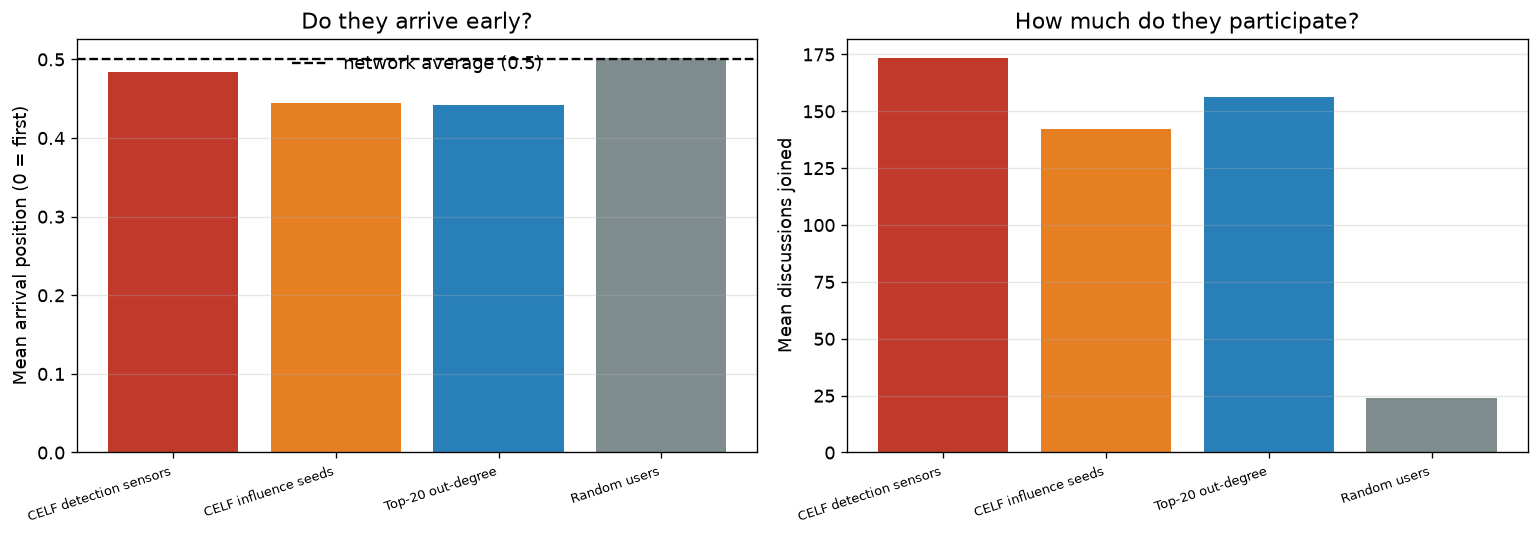

In [6]:
fig,ax=plt.subplots(1,2,figsize=(13,4.6))
labels=[g["group"] for g in groups]; x=np.arange(len(labels))
cols=["#c0392b","#e67e22","#2980b9","#7f8c8d"][:len(labels)]

ax[0].bar(x,[g["mean_position"] for g in groups],color=cols)
ax[0].axhline(0.5,color="black",ls="--",lw=1.4,label="network average (0.5)")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels,rotation=18,ha="right",fontsize=8)
ax[0].set_ylabel("Mean arrival position (0 = first)")
ax[0].set_title("Do they arrive early?"); ax[0].legend(frameon=False); ax[0].grid(alpha=.3,axis="y")

ax[1].bar(x,[g["mean_discussions_joined"] for g in groups],color=cols)
ax[1].set_xticks(x); ax[1].set_xticklabels(labels,rotation=18,ha="right",fontsize=8)
ax[1].set_ylabel("Mean discussions joined")
ax[1].set_title("How much do they participate?"); ax[1].grid(alpha=.3,axis="y")
plt.tight_layout(); plt.savefig("figures/fig_APP3_validation.png",bbox_inches="tight"); plt.show()

## 3.6 — Do sensors spread across communities? (APP-4)

Same non-redundancy logic as Section 2. Twenty sensors all watching the same corner of the
network would be wasteful, however individually active they are.

Temper expectations: modularity was only **Q ~ 0.13**, so communities barely separate in this
network. A weak effect here is consistent with Block B, not a failure.

,community,nodes,share_pct,sensors,expected,over_under
0,2,1614,25.1,5,5.02,-0.02
1,0,1427,22.2,10,4.44,5.56
2,3,1069,16.6,2,3.32,-1.32
3,5,737,11.5,1,2.29,-1.29
4,4,504,7.8,0,1.57,-1.57
5,1,434,6.7,0,1.35,-1.35
6,7,424,6.6,1,1.32,-0.32
7,6,225,3.5,1,0.70,0.30



sensors occupy 6 of 8 substantial communities
most sensors in any one community: 10 of 20
SPREAD across communities


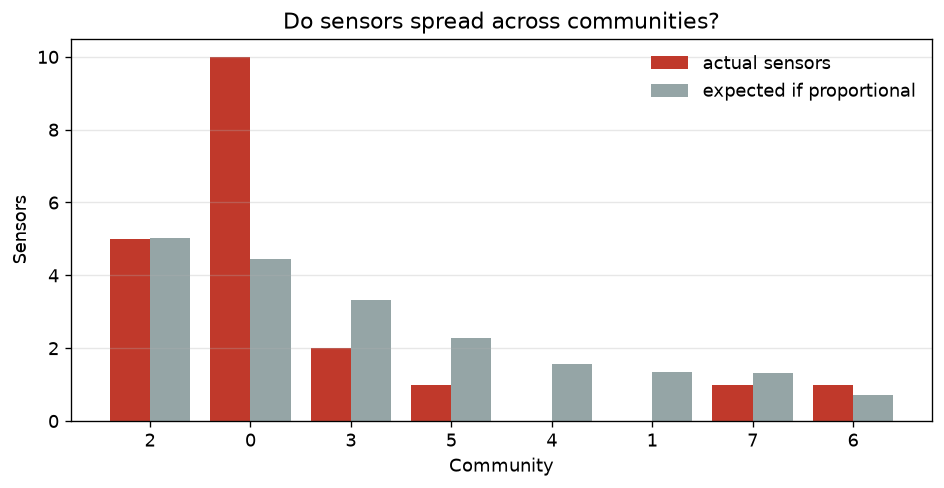

In [7]:
try:
    m=pd.read_csv("data/gephi_node_metrics.csv")
    idc="Id" if "Id" in m.columns else m.columns[0]
    modcol=[x for x in m.columns if "odularity" in x.lower().replace(" ","")][0]
    comm_h=dict(zip(m[idc],m[modcol]))
    comm={h2u[h]:c_ for h,c_ in comm_h.items() if h in h2u}
    sizes=Counter(comm.values()); N=len(comm)
    k=20; S=sensors[:k]
    got=Counter(comm.get(u) for u in S if comm.get(u) is not None)

    rows=[]
    for cid,size in sorted(sizes.items(),key=lambda x:-x[1]):
        rows.append({"community":cid,"nodes":size,"share_pct":round(100*size/N,1),
                     "sensors":got.get(cid,0),"expected":round(k*size/N,2),
                     "over_under":round(got.get(cid,0)-k*size/N,2)})
    cov=pd.DataFrame(rows); display(cov)
    cov.to_csv("figures/blockAPP4_sensor_communities.csv",index=False)

    big=[cid for cid,s in sizes.items() if s>=20]
    print(f"\nsensors occupy {len([x for x in got if x is not None])} of {len(big)} substantial communities")
    print(f"most sensors in any one community: {max(got.values())} of {k}")
    print("SPREAD across communities" if max(got.values())/k<=0.6 else "CLUSTERED in one community")

    fig,ax=plt.subplots(figsize=(8,4.2))
    xx=np.arange(len(cov))
    ax.bar(xx-0.2,cov.sensors,0.4,label="actual sensors",color="#c0392b")
    ax.bar(xx+0.2,cov.expected,0.4,label="expected if proportional",color="#95a5a6")
    ax.set_xticks(xx); ax.set_xticklabels(cov.community)
    ax.set_xlabel("Community"); ax.set_ylabel("Sensors")
    ax.set_title("Do sensors spread across communities?")
    ax.legend(frameon=False); ax.grid(alpha=.3,axis="y")
    plt.tight_layout(); plt.savefig("figures/fig_APP4_sensor_communities.png",bbox_inches="tight"); plt.show()
except FileNotFoundError:
    print("data/gephi_node_metrics.csv not found - run section1b_local_metrics.ipynb first")
except IndexError:
    print("no modularity column found - run Louvain (section1b) first")

## What to write up

**From 3.5 (APP-3):** state plainly whether influential users arrive early. If mean position sits
near 0.5, the honest conclusion is:

> *"High-activity users do not systematically initiate discussions; they join at typical points.
> The detection advantage therefore derives from breadth of participation rather than precocity.
> This refines the influence interpretation: in a reply network, 'influence' as measured here
> reflects sustained presence across many conversations rather than being first to speak."*

That is a **better** finding than a convenient confirmation - it is a real empirical result that
constrains how the model should be read, and it directly addresses the reply-is-not-adoption
limitation you have carried since the dataset phase.

**From 3.6 (APP-4):** report the sensor distribution and connect it to the weak modularity (Q~0.13).